In [36]:
from sklearn.datasets import load_digits

digits = load_digits()

In [37]:
digits.images[13]

array([[ 0.,  2.,  9., 15., 14.,  9.,  3.,  0.],
       [ 0.,  4., 13.,  8.,  9., 16.,  8.,  0.],
       [ 0.,  0.,  0.,  6., 14., 15.,  3.,  0.],
       [ 0.,  0.,  0., 11., 14.,  2.,  0.,  0.],
       [ 0.,  0.,  0.,  2., 15., 11.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  2., 15.,  4.,  0.],
       [ 0.,  1.,  5.,  6., 13., 16.,  6.,  0.],
       [ 0.,  2., 12., 12., 13., 11.,  0.,  0.]])

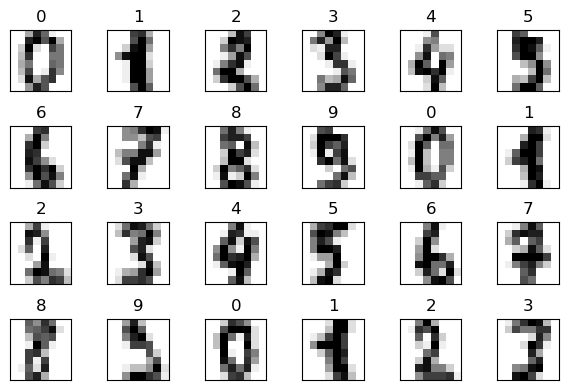

In [38]:
import matplotlib.pyplot as plt
figure, axes = plt.subplots(nrows =4, ncols=6, figsize=(6,4))

for item in zip(axes.ravel(), digits.images, digits.target):
    axes, image, target = item
    axes.imshow(image, cmap=plt.cm.gray_r)

    axes.set_xticks([])
    axes.set_yticks([])
    axes.set_title(target)
plt.tight_layout()

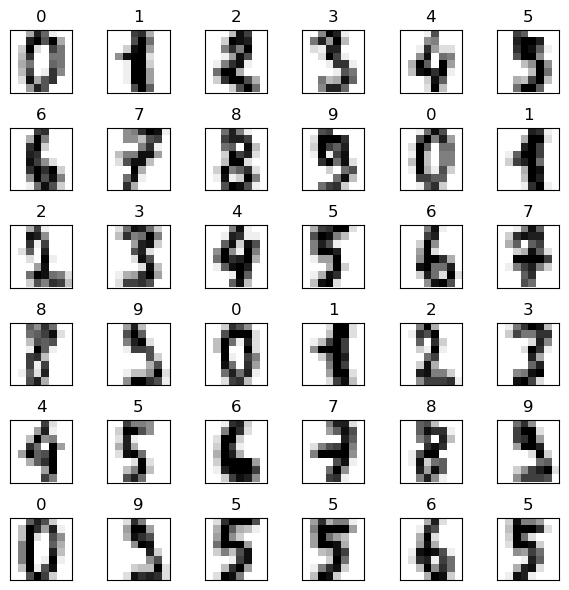

In [39]:
import matplotlib.pyplot as plt
figure, axes = plt.subplots(nrows =6, ncols=6, figsize=(6,6))

for item in zip(axes.ravel(), digits.images, digits.target):
    axes, image, target = item
    axes.imshow(image, cmap=plt.cm.gray_r)

    axes.set_xticks([])
    axes.set_yticks([])
    axes.set_title(target)
plt.tight_layout()

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, random_state=11)


In [41]:
X_train.shape

(1347, 64)

In [42]:
X_test.shape

(450, 64)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, random_state=11, test_size=0.20)

In [44]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

In [45]:
knn.fit(X=X_train, y=y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [46]:
predicted = knn.predict(X=X_test)
expected = y_test

In [66]:
print(predicted[:36])
print(expected[:36])

[0 4 9 9 3 1 4 1 5 0 4 9 4 1 5 3 3 8 5 6 9 6 0 6 9 3 2 1 8 1 7 0 4 4 1 5]
[0 4 9 9 3 1 4 1 5 0 4 9 4 1 5 3 3 8 3 6 9 6 0 6 9 3 2 1 8 1 7 0 4 4 1 5]


In [49]:
print(f'{knn.score(X_test, y_test):.2%}')

98.61%


In [50]:
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_true=expected, y_pred=predicted)

In [51]:
confusion

array([[38,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 37,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0, 39,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 39,  0,  1,  0,  1,  0,  0],
       [ 0,  0,  0,  0, 40,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  0,  0, 27,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 30,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 36,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 34,  0],
       [ 0,  0,  0,  0,  1,  0,  0,  0,  1, 35]])

In [52]:
from sklearn.metrics import classification_report

names=[str(digit) for digit in digits.target_names]

print(classification_report(expected, predicted, target_names = names))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        39
           3       1.00      0.95      0.97        41
           4       0.98      0.98      0.98        41
           5       0.96      1.00      0.98        27
           6       1.00      1.00      1.00        30
           7       0.95      1.00      0.97        36
           8       0.97      1.00      0.99        34
           9       1.00      0.95      0.97        37

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [65]:
from sklearn.svm import SVC

svm =  SVC(kernel="rbf", C=10, gamma=0.001)
svm.fit(X=X_train, y=y_train)

predicted_svm = svm.predict(X=X_test)
expected_svm = y_test

print(predicted_svm[:36])
print(expected_svm[:36])

[0 4 9 9 3 1 4 1 5 0 4 9 4 1 5 3 3 8 5 6 9 6 0 6 9 3 2 1 8 1 7 0 4 4 1 5]
[0 4 9 9 3 1 4 1 5 0 4 9 4 1 5 3 3 8 3 6 9 6 0 6 9 3 2 1 8 1 7 0 4 4 1 5]


In [55]:
print(f'score: {svm.score(X_test, y_test):.2%}')
confusion_svm = confusion_matrix(y_true=expected_svm, y_pred=predicted_svm)
confusion_svm

score: 98.61%


array([[38,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 37,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0, 39,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 38,  0,  1,  0,  1,  1,  0],
       [ 0,  0,  0,  0, 41,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 27,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 30,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 35,  0,  1],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 34,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  1,  0, 36]])

In [56]:
print(classification_report(expected_svm, predicted_svm, target_names = names))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        39
           3       1.00      0.93      0.96        41
           4       1.00      1.00      1.00        41
           5       0.96      1.00      0.98        27
           6       1.00      1.00      1.00        30
           7       0.95      0.97      0.96        36
           8       0.97      1.00      0.99        34
           9       0.97      0.97      0.97        37

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [64]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X=X_train, y=y_train)

predicted_gnb = gnb.predict(X=X_test)
expected_gnb = y_test

print(predicted_gnb[:36])
print(expected_gnb[:36])


[0 4 7 9 3 8 4 1 5 0 7 9 4 1 5 3 3 8 5 6 9 4 0 6 9 3 2 1 8 1 7 0 4 4 1 5]
[0 4 9 9 3 1 4 1 5 0 4 9 4 1 5 3 3 8 3 6 9 6 0 6 9 3 2 1 8 1 7 0 4 4 1 5]


In [59]:
print(f'score: {gnb.score(X_test, y_test):.2%}')
confusion_gnb = confusion_matrix(y_true=expected_gnb, y_pred=predicted_gnb)
confusion_gnb

score: 85.56%


array([[36,  0,  0,  0,  1,  0,  0,  1,  0,  0],
       [ 0, 31,  0,  0,  0,  0,  0,  1,  3,  2],
       [ 0,  1, 34,  0,  0,  0,  0,  0,  4,  0],
       [ 0,  1,  0, 33,  0,  2,  0,  2,  3,  0],
       [ 0,  0,  0,  0, 36,  0,  0,  5,  0,  0],
       [ 0,  0,  0,  0,  0, 27,  0,  0,  0,  0],
       [ 0,  0,  1,  0,  1,  0, 28,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 36,  0,  0],
       [ 0,  3,  0,  1,  0,  1,  0,  4, 25,  0],
       [ 1,  2,  0,  0,  1,  0,  0,  8,  3, 22]])

In [60]:
print(classification_report(expected_gnb, predicted_gnb, target_names = names))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96        38
           1       0.82      0.84      0.83        37
           2       0.97      0.87      0.92        39
           3       0.97      0.80      0.88        41
           4       0.92      0.88      0.90        41
           5       0.90      1.00      0.95        27
           6       1.00      0.93      0.97        30
           7       0.63      1.00      0.77        36
           8       0.66      0.74      0.69        34
           9       0.92      0.59      0.72        37

    accuracy                           0.86       360
   macro avg       0.88      0.86      0.86       360
weighted avg       0.88      0.86      0.86       360



In [69]:
for k in range(1, 21, 2):
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    score =  knn_model.score(X_test, y_test)
    
    print(f"k = {k}, score = {score:.2%}")

k = 1, score = 98.61%
k = 3, score = 98.89%
k = 5, score = 98.61%
k = 7, score = 98.33%
k = 9, score = 98.33%
k = 11, score = 98.61%
k = 13, score = 98.33%
k = 15, score = 97.78%
k = 17, score = 97.78%
k = 19, score = 97.22%
